Step 4: Create Platform and Campaign Charts (10,000 Records)

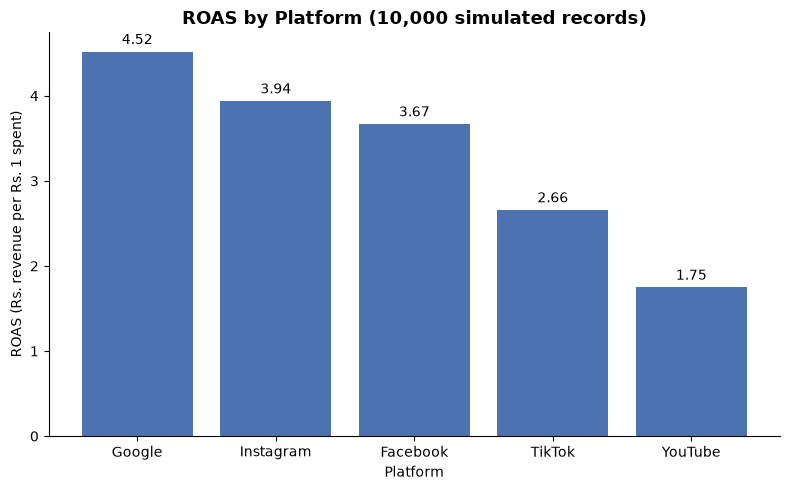

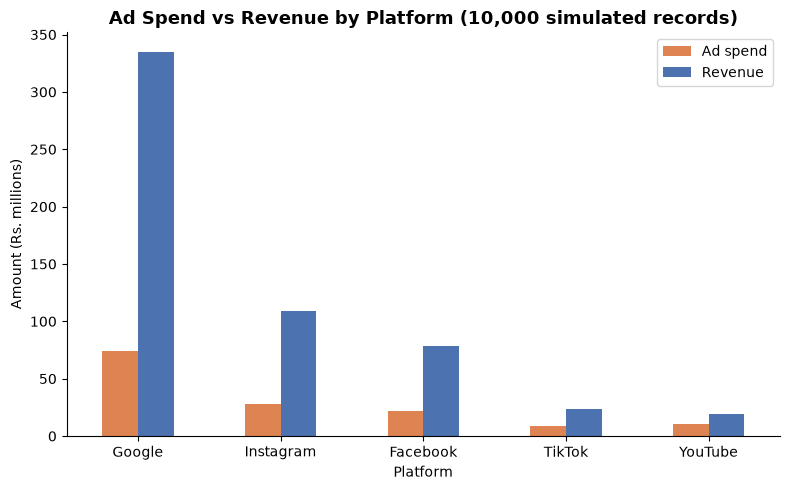

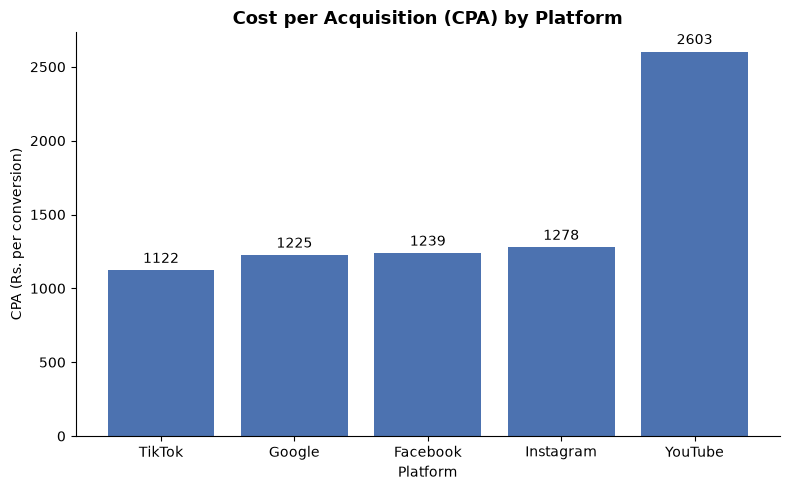

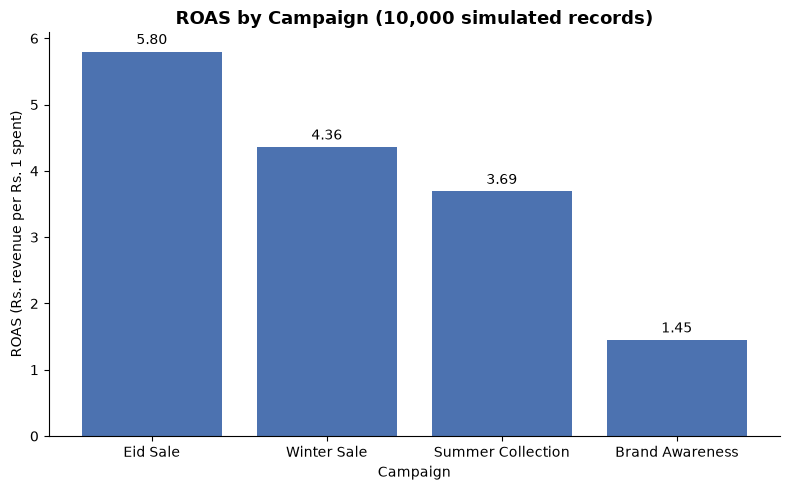

Saved 4 charts to outputs/figures/


In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd
from metrics import summarize

FIG_DIR = "../outputs/figures/"

# Load raw data (read-only) and calculate metrics
df = pd.read_csv("../data/raw/ads_10k.csv", parse_dates=["date"])
platform = summarize(df, "platform").sort_values("roas", ascending=False)
campaign = summarize(df, "campaign").sort_values("roas", ascending=False)


def bar_chart(series, title, xlabel, ylabel, filename, fmt="%.2f"):
    """Draw a labelled bar chart and save it as a PNG."""
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(series.index, series.values, color="#4C72B0")
    ax.bar_label(bars, fmt=fmt, padding=3)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR + filename, dpi=200)
    plt.show()


# Chart 1: ROAS by platform
bar_chart(platform["roas"],
          "ROAS by Platform (10,000 simulated records)",
          "Platform", "ROAS (Rs. revenue per Rs. 1 spent)",
          "01_roas_by_platform.png")

# Chart 2: Spend vs revenue by platform
fig, ax = plt.subplots(figsize=(8, 5))
spend_revenue = (platform[["spend", "revenue"]] / 1e6).rename(
    columns={"spend": "Ad spend", "revenue": "Revenue"})
spend_revenue.plot(kind="bar", ax=ax, color=["#DD8452", "#4C72B0"], rot=0)
ax.set_title("Ad Spend vs Revenue by Platform (10,000 simulated records)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Platform")
ax.set_ylabel("Amount (Rs. millions)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR + "02_spend_vs_revenue.png", dpi=200)
plt.show()

# Chart 3: Cost per acquisition by platform (lower is better)
bar_chart(platform["cpa"].sort_values(),
          "Cost per Acquisition (CPA) by Platform",
          "Platform", "CPA (Rs. per conversion)",
          "03_cpa_by_platform.png", fmt="%.0f")

# Chart 4: ROAS by campaign
bar_chart(campaign["roas"],
          "ROAS by Campaign (10,000 simulated records)",
          "Campaign", "ROAS (Rs. revenue per Rs. 1 spent)",
          "04_roas_by_campaign.png")

print("Saved 4 charts to outputs/figures/")